### Data Preprocessing

#### Import

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, f_oneway, tukey_hsd, pearsonr
reviews = pd.read_csv("rotten_tomatoes_movie_reviews.csv")
movies = pd.read_csv("rotten_tomatoes_movies.csv")

#### Parse

In [3]:
# We will start parsing by removing duplicate movies and reviews
movies = movies.drop_duplicates(subset='id')

# We turn Box Office sales from strings with letters (e.g 'M' for million) into dollar amounts
movies['boxOffice'] = movies['boxOffice'].str.replace('$', '').str.replace('M', 'e6').str.replace('K', 'e3')
movies['boxOffice'] = pd.to_numeric(movies['boxOffice'], errors='coerce')

# Now we convert release dates and review dates from text to datetime
movies['releaseDateTheaters'] = pd.to_datetime(movies['releaseDateTheaters'], errors='coerce')
movies['releaseDateStreaming'] = pd.to_datetime(movies['releaseDateStreaming'], errors='coerce')

# The genre can be a list of multiple genres, so we take the first one as the movie’s main genre
movies['primaryGenre'] = movies['genre'].str.split(',').str[0]

# Define the difference in scores
movies['scoreGap'] = movies['audienceScore'] - movies['tomatoMeter']

movies[['title', 'tomatoMeter', 'audienceScore', 'scoreGap', 'primaryGenre', 'boxOffice']].head()

,title,tomatoMeter,audienceScore,scoreGap,primaryGenre,boxOffice
0,Space Zombie Bingo!,NaN,50.0,NaN,Comedy,NaN
1,The Green Grass,NaN,NaN,NaN,Drama,NaN
2,"Love, Lies",NaN,43.0,NaN,Drama,NaN
3,Sore Losers,NaN,60.0,NaN,Action,NaN
4,Dinosaur Island,NaN,70.0,NaN,Fantasy,NaN


In [4]:
# Removing duplicates
reviews = reviews.drop_duplicates(subset='reviewId')
reviews['creationDate'] = pd.to_datetime(reviews['creationDate'], errors='coerce')

# In the raw data, the critics' original scores are in different formats such as ("3/4", "8/10", "B+")
# We can convert the fraction ones to a [0-1] scale so they can be compared (other formats become NaN)
parts = reviews['originalScore'].str.split('/', expand=True)
reviews['scoreNorm'] = pd.to_numeric(parts[0], errors='coerce') / pd.to_numeric(parts[1], errors='coerce')
reviews.loc[reviews['scoreNorm'] > 1, 'scoreNorm'] = np.nan

reviews['isFresh'] = reviews['reviewState'] == 'fresh'

reviews[['originalScore', 'scoreNorm', 'reviewState', 'isFresh']].head()

,originalScore,scoreNorm,reviewState,isFresh
0,3.5/4,0.875,fresh,True
1,1/5,0.200,rotten,False
2,NaN,NaN,fresh,True
3,2.5/5,0.500,rotten,False
4,NaN,NaN,fresh,True


#### Organize

In [5]:
# Count each movie's reviews and its percentage of Fresh reviews
review_counts = reviews.groupby('id').agg(numReviews=('reviewId', 'count'), freshRate=('isFresh', 'mean')).reset_index()
movies = movies.merge(review_counts, on='id', how='left')
display(movies.head())

# Keep movies with both an audience and Tomatometer (critic) score
scored = movies.dropna(subset=['tomatoMeter', 'audienceScore'])
scored[['tomatoMeter', 'audienceScore', 'scoreGap', 'runtimeMinutes', 'numReviews']].describe()

,id,title,audienceScore,tomatoMeter,rating,ratingContents,releaseDateTheaters,releaseDateStreaming,runtimeMinutes,genre,originalLanguage,director,writer,boxOffice,distributor,soundMix,primaryGenre,scoreGap,numReviews,freshRate
0,space-zombie-bingo,Space Zombie Bingo!,50.0,NaN,NaN,NaN,NaT,2018-08-25,75.0,"Comedy, Horror, Sci-fi",English,George Ormrod,"George Ormrod,John Sabotta",NaN,NaN,NaN,Comedy,NaN,NaN,NaN
1,the_green_grass,The Green Grass,NaN,NaN,NaN,NaN,NaT,2020-02-11,114.0,Drama,English,Tiffany Edwards,Tiffany Edwards,NaN,NaN,NaN,Drama,NaN,NaN,NaN
2,love_lies,"Love, Lies",43.0,NaN,NaN,NaN,NaT,NaT,120.0,Drama,Korean,"Park Heung-Sik,Heung-Sik Park","Ha Young-Joon,Jeon Yun-su,Song Hye-jin",NaN,NaN,NaN,Drama,NaN,2.0,1.0
3,the_sore_losers_1997,Sore Losers,60.0,NaN,NaN,NaN,NaT,2020-10-23,90.0,"Action, Mystery & thriller",English,John Michael McCarthy,John Michael McCarthy,NaN,NaN,NaN,Action,NaN,NaN,NaN
4,dinosaur_island_2002,Dinosaur Island,70.0,NaN,NaN,NaN,NaT,2017-03-27,80.0,"Fantasy, Adventure, Animation",English,Will Meugniot,John Loy,NaN,NaN,NaN,Fantasy,NaN,NaN,NaN


,tomatoMeter,audienceScore,scoreGap,runtimeMinutes,numReviews
count,30052.000000,30052.000000,30052.000000,29367.000000,29854.000000
mean,64.525090,62.310229,-2.214861,101.506453,44.397836
std,28.045784,20.862795,22.745236,21.090280,61.756210
min,0.000000,0.000000,-100.000000,5.000000,1.000000
25%,43.000000,47.000000,-17.000000,90.000000,9.000000
50%,71.000000,65.000000,-4.000000,98.000000,19.000000
75%,88.000000,79.000000,11.000000,110.000000,51.000000
max,100.000000,100.000000,100.000000,584.000000,597.000000


### Data Exploration

## Hypothesis 1: Is there a difference between audience and critic scores?

> H0: There is no difference between audience and critic scores. The mean of (audience score - critic score) is 0.

> HA: There is a difference between audience and critic scores. The mean of (audience score - critic score) is not 0.

Use a **paired t-test** because every movie has both an audience score and a critic score, so the two samples are paired and not independent. Our sample is very large, so by the CLT the mean difference is approximately normal.

In [6]:
t_stat, p = ttest_rel(scored['audienceScore'], scored['tomatoMeter'])
print("mean critic score:", scored['tomatoMeter'].mean())
print("mean audience score:", scored['audienceScore'].mean())
print("mean gap:", scored['scoreGap'].mean())
print("t-statistic:", t_stat)
print("p-value:", p)

mean critic score: 64.52508984426993
mean audience score: 62.31022893651005
mean gap: -2.214860907759883
t-statistic: -16.880787311225728
p-value: 1.2249939881945988e-63


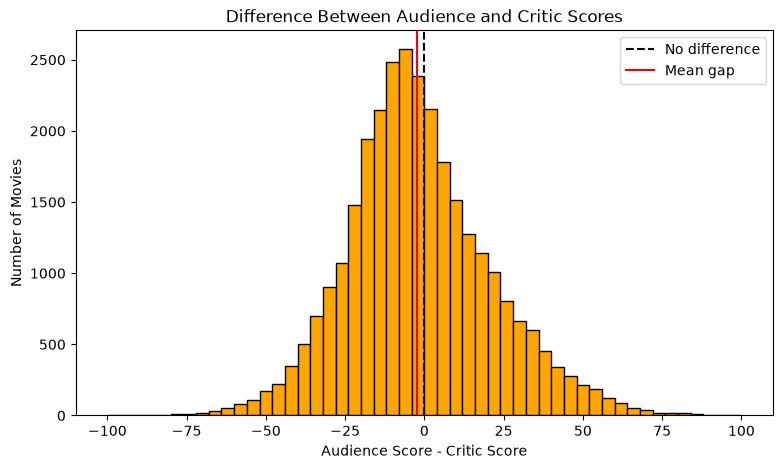

In [7]:
plt.figure(figsize=(9, 5))
plt.hist(scored['scoreGap'], bins=50, color='orange', edgecolor='black')
plt.axvline(0, color='black', linestyle='--', label='No difference')
plt.axvline(scored['scoreGap'].mean(), color='red', label='Mean gap')
plt.xlabel('Audience Score - Critic Score')
plt.ylabel('Number of Movies')
plt.title('Difference Between Audience and Critic Scores')
plt.legend()
plt.show()

Conclusion: The p-value is 1.22e-63, which is less than 0.05, so we reject the null hypothesis. There is a significant difference between audience and critic scores. On average, critics score movies 2.2 points higher than audiences (64.5 vs. 62.3).

## Hypothesis 2: Is the gap wider in certain genres?

> H0: Genre has no effect on the gap. The mean score gap is the same for all genres.

> HA: Genre does have an effect on the gap. At least one genre has a different mean score gap.

Use a **one-way ANOVA** because we're comparing the mean of one numeric variable (score gap) across more than 2 groups. We use each movie's first genre so no movie is counted twice, and only the 6 most common genres so each group has enough movies.

In [8]:
top_genres = scored['primaryGenre'].value_counts().head(6).index
groups = [scored[scored['primaryGenre'] == g]['scoreGap'] for g in top_genres]

f_stat, p = f_oneway(*groups)
print(scored[scored['primaryGenre'].isin(top_genres)].groupby('primaryGenre')['scoreGap'].mean())
print("\nF-statistic:", f_stat)
print("p-value:", p)

primaryGenre
Action                4.309567
Comedy                0.510465
Documentary          -8.336466
Drama                -3.541595
Horror               -8.366013
Mystery & thriller   -2.349590
Name: scoreGap, dtype: float64

F-statistic: 130.1193597485045
p-value: 2.4682787613961708e-136


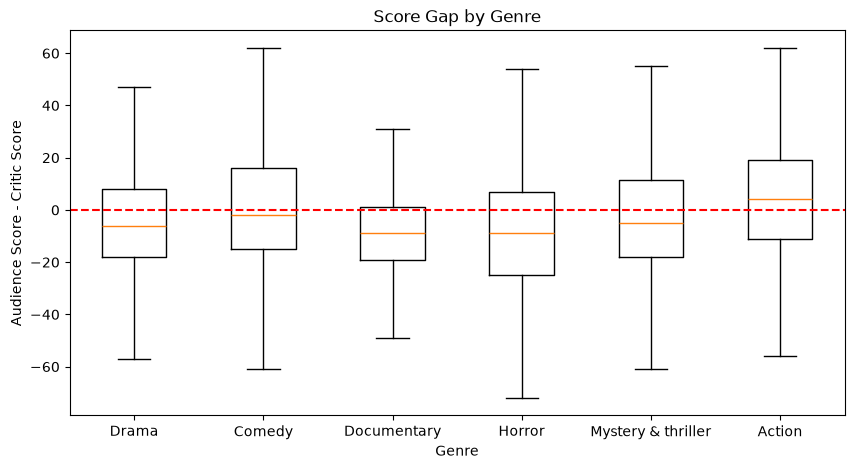

In [9]:
plt.figure(figsize=(10, 5))
plt.boxplot(groups, tick_labels=top_genres, showfliers=False)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Genre')
plt.ylabel('Audience Score - Critic Score')
plt.title('Score Gap by Genre')
plt.show()

Since ANOVA only tells us that at least one genre is different, we use Tukey's HSD to see which pairs of genres are different (0 to 5 follow the order of `top_genres`).

In [10]:
print(list(top_genres))
print(tukey_hsd(*groups))

['Drama', 'Comedy', 'Documentary', 'Horror', 'Mystery & thriller', 'Action']
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -4.052     0.000    -5.209    -2.895
 (0 - 2)      4.795     0.000     3.511     6.079
 (0 - 3)      4.824     0.000     3.246     6.402
 (0 - 4)     -1.192     0.274    -2.791     0.407
 (0 - 5)     -7.851     0.000    -9.604    -6.098
 (1 - 0)      4.052     0.000     2.895     5.209
 (1 - 2)      8.847     0.000     7.496    10.197
 (1 - 3)      8.876     0.000     7.244    10.509
 (1 - 4)      2.860     0.000     1.208     4.512
 (1 - 5)     -3.799     0.000    -5.601    -1.997
 (2 - 0)     -4.795     0.000    -6.079    -3.511
 (2 - 1)     -8.847     0.000   -10.197    -7.496
 (2 - 3)      0.030     1.000    -1.695     1.754
 (2 - 4)     -5.987     0.000    -7.731    -4.243
 (2 - 5)    -12.646     0.000   -14.532   -10.760
 (3 - 0)     -4.824     0.000    -6.402    -3.246
 (3 - 1)     -8.8

Conclusion: The ANOVA p-value is 2.47e-136, which is less than 0.05, so we reject the null hypothesis. The gap between audience and critic scores depends on genre. Tukey’s HSD shows 13 of 15 genre pairs are significantly different. Action has the highest mean gap, meaning audiences rate it most favorably compared to critics, followed by Comedy. Documentary and Horror have the lowest mean gaps, meaning critics rate them most favorably compared to audiences. The only pairs that are not significantly different are Drama vs. Mystery & thriller and Documentary vs. Horror.

## Hypothesis 3: Is a movie's critic score related to its audience score?

> H0: There is no correlation between critic score and audience score.

> HA: There is a correlation between critic score and audience score.

We use **Pearson correlation** since both variables are numeric and we want to see how strongly they're related. This matters for our plan to predict audience score from critic score later.

In [11]:
corr, p = pearsonr(scored['tomatoMeter'], scored['audienceScore'])
print("correlation:", corr)
print("p-value:", p)

correlation: 0.6019998725489482
p-value: 0.0


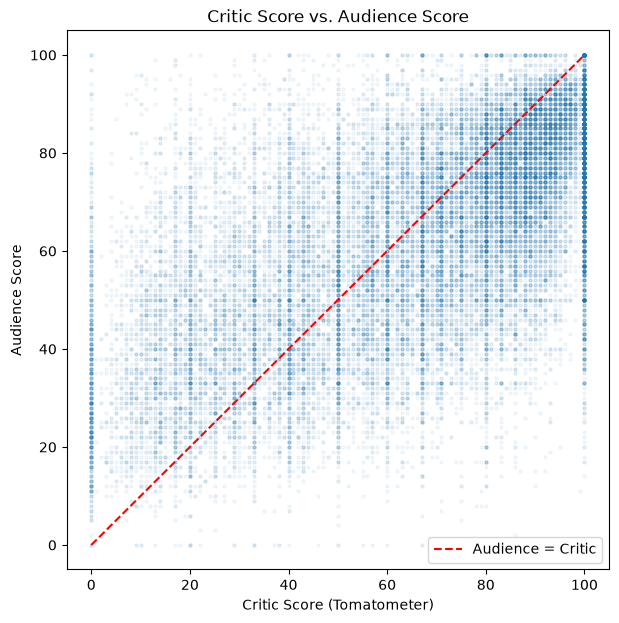

In [12]:
plt.figure(figsize=(7, 7))
plt.scatter(scored['tomatoMeter'], scored['audienceScore'], alpha=0.05, s=5)
plt.plot([0, 100], [0, 100], color='red', linestyle='--', label='Audience = Critic')
plt.xlabel('Critic Score (Tomatometer)')
plt.ylabel('Audience Score')
plt.title('Critic Score vs. Audience Score')
plt.legend()
plt.show()

Conclusion: The p-value is so small it shows as 0.0, which is less than 0.05, so we reject the null hypothesis. There is a strong positive correlation between critic and audience scores (r = 0.60). The plot shows audiences are less extreme than critics: they score movies higher than critics when critics score low, and lower when critics score high.